# Customer Lifetime Value (CLV) Prediction
**Course:** Machine Learning for Business Applications | **Assignment 2** | **Task type:** Regression

## Part A - Business Problem
**Business Problem:** An auto insurance company does not know which customers will be worth the most over the long run. Marketing and retention money is limited, so it must be spent on the right customers.

**Analytics Objective:** Build a regression model that predicts the Customer Lifetime Value (CLV) of a customer in dollars.

**Target Variable:** `Customer Lifetime Value` (the net profit the company earns from a customer over the time they stay).

**Business Decision:** Customers with a high predicted CLV get priority for retention offers, better service and cross-selling. Customers with a low predicted CLV get low-cost, automated marketing.

## Dataset Information
| Item | Detail |
|---|---|
| Name | Auto Insurance Customer Lifetime Value (IBM Watson Marketing Customer Value Analysis) |
| Source | Public dataset, widely shared on Kaggle (copy used from a public GitHub repo: Sarah-2510/Customer-Lifetime-Value-Prediction) |
| Rows | 9,134 |
| Columns | 24 |
| Target | Customer Lifetime Value |


## Part B - Data Preparation
### 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/dataset.csv")
df.head()

,Customer,State,Response,Coverage,Education,Effective To Date,EmploymentStatus,Gender,Income,Location Code,...,Number of Open Complaints,Number of Policies,Policy Type,Policy,Renew Offer Type,Sales Channel,Total Claim Amount,Vehicle Class,Vehicle Size,Customer Lifetime Value
0,BU79786,Washington,No,Basic,Bachelor,2/24/11,Employed,F,56274,Suburban,...,0,1,Corporate Auto,Corporate L3,Offer1,Agent,384.811147,Two-Door Car,Medsize,2763.519279
1,QZ44356,Arizona,No,Extended,Bachelor,1/31/11,Unemployed,F,0,Suburban,...,0,8,Personal Auto,Personal L3,Offer3,Agent,1131.464935,Four-Door Car,Medsize,6979.535903
2,AI49188,Nevada,No,Premium,Bachelor,2/19/11,Employed,F,48767,Suburban,...,0,2,Personal Auto,Personal L3,Offer1,Agent,566.472247,Two-Door Car,Medsize,12887.431650
3,WW63253,California,No,Basic,Bachelor,1/20/11,Unemployed,M,0,Suburban,...,0,7,Corporate Auto,Corporate L2,Offer1,Call Center,529.881344,SUV,Medsize,7645.861827
4,HB64268,Washington,No,Basic,Bachelor,2/3/11,Employed,M,43836,Rural,...,0,1,Personal Auto,Personal L1,Offer1,Agent,138.130879,Four-Door Car,Medsize,2813.692575


### 2. Understand the data

In [2]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (9134, 24)
<class 'pandas.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   str    
 1   State                          9134 non-null   str    
 2   Response                       9134 non-null   str    
 3   Coverage                       9134 non-null   str    
 4   Education                      9134 non-null   str    
 5   Effective To Date              9134 non-null   str    
 6   EmploymentStatus               9134 non-null   str    
 7   Gender                         9134 non-null   str    
 8   Income                         9134 non-null   int64  
 9   Location Code                  9134 non-null   str    
 10  Marital Status                 9134 non-null   str    
 11  Monthly Premium Auto           9134 non-null   int64  
 12  Months Since Last Claim  

In [3]:
df.describe()

,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount,Customer Lifetime Value
count,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000
mean,37657.380009,93.219291,15.097000,48.064594,0.384388,2.966170,434.088794,8004.940475
std,30379.904734,34.407967,10.073257,27.905991,0.910384,2.390182,290.500092,6870.967608
min,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007,1898.007675
25%,0.000000,68.000000,6.000000,24.000000,0.000000,1.000000,272.258244,3994.251794
50%,33889.500000,83.000000,14.000000,48.000000,0.000000,2.000000,383.945434,5780.182197
75%,62320.000000,109.000000,23.000000,71.000000,0.000000,4.000000,547.514839,8962.167041
max,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678,83325.381190


### 3. Clean the data

In [4]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["Customer"].duplicated().sum())

Missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0


There are no missing values and no duplicates, so no rows need to be removed.

**Date column:** `Effective To Date` is a text column. We convert it to a date to check it, but we do not use it as a predictor.

In [5]:
df["Effective To Date"] = pd.to_datetime(df["Effective To Date"], format="%m/%d/%y")
print(df["Effective To Date"].min(), "to", df["Effective To Date"].max())

2011-01-01 00:00:00 to 2011-02-28 00:00:00


**Outliers:** CLV is right-skewed (a few customers are worth a lot more than the rest). We check it with the IQR rule, but we KEEP these customers. They are exactly the high-value customers the business cares about.

In [6]:
q1 = df["Customer Lifetime Value"].quantile(0.25)
q3 = df["Customer Lifetime Value"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
n_out = (df["Customer Lifetime Value"] > upper).sum()
print("Upper limit:", round(upper), "| customers above it:", n_out, "(", round(n_out / len(df) * 100, 1), "% )")

Upper limit: 16414 | customers above it: 817 ( 8.9 % )


### 4. Feature preparation
- **Target (y):** `Customer Lifetime Value`
- **Dropped (not useful):** `Customer` (just an ID), `Effective To Date` (a date, not a customer trait)
- **Numerical predictors:** Monthly Premium Auto, Number of Policies, Income, Total Claim Amount, Months Since Last Claim, Months Since Policy Inception
- **Categorical predictors:** Coverage, Vehicle Class

We use these 8 predictors. In our testing, using all other columns gave almost the same accuracy, so we keep the model simple so users only need to fill in 8 boxes in the app.

## Part C - Exploratory Data Analysis

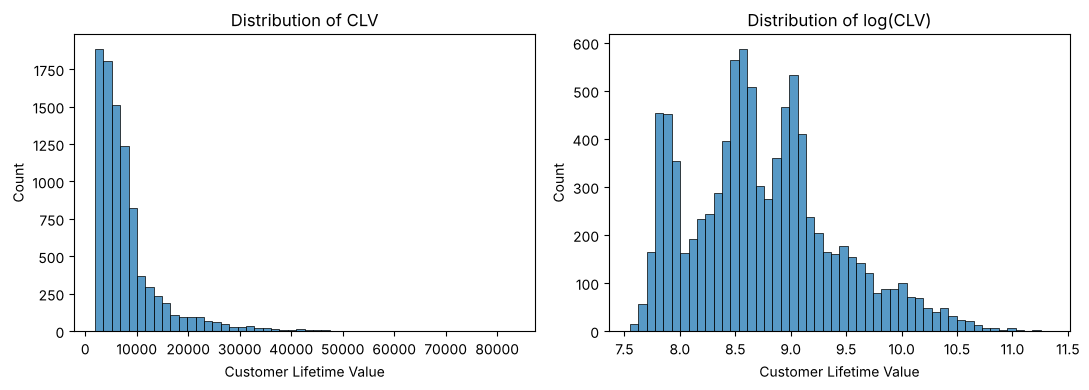

Mean: 8005 | Median: 5780


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df["Customer Lifetime Value"], bins=50, ax=ax[0])
ax[0].set_title("Distribution of CLV")
sns.histplot(np.log(df["Customer Lifetime Value"]), bins=50, ax=ax[1])
ax[1].set_title("Distribution of log(CLV)")
plt.tight_layout()
plt.savefig("../images/clv_distribution.png", dpi=120)
plt.show()
print("Mean:", round(df["Customer Lifetime Value"].mean()), "| Median:", round(df["Customer Lifetime Value"].median()))

**What it tells the manager:** Most customers are worth less than about $9,000, but a small group is worth much more (the mean is above the median). So a small share of customers brings in a big share of the value. This is why the company needs to find them early.

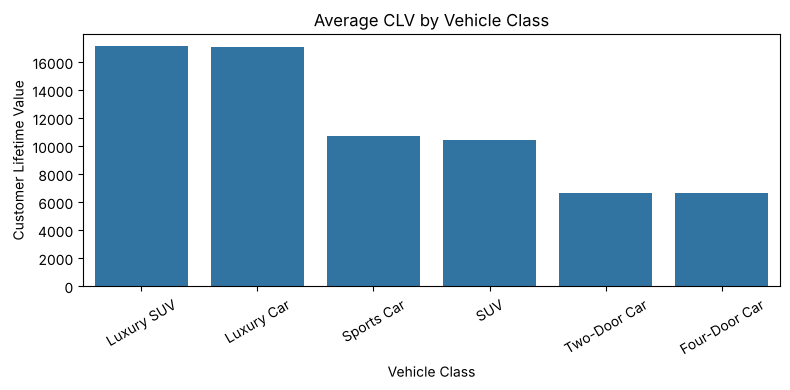

Vehicle Class
Luxury SUV       17123.0
Luxury Car       17053.0
Sports Car       10751.0
SUV              10444.0
Two-Door Car      6671.0
Four-Door Car     6632.0
Name: Customer Lifetime Value, dtype: float64


In [8]:
order = df.groupby("Vehicle Class")["Customer Lifetime Value"].mean().sort_values(ascending=False).index
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="Vehicle Class", y="Customer Lifetime Value", order=order, estimator="mean", errorbar=None)
plt.xticks(rotation=30)
plt.title("Average CLV by Vehicle Class")
plt.tight_layout()
plt.savefig("../images/clv_by_vehicle_class.png", dpi=120)
plt.show()
print(df.groupby("Vehicle Class")["Customer Lifetime Value"].mean().round(0).sort_values(ascending=False))

**What it tells the manager:** Luxury SUV and Luxury Car owners are worth about $17,000 on average, more than double the owners of Four-Door and Two-Door cars (about $6,600). Marketing for premium service and retention should focus on the luxury segment.

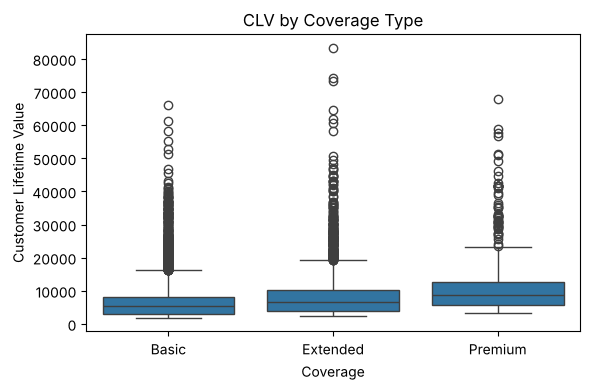

Coverage
Basic        7191.0
Extended     8790.0
Premium     10896.0
Name: Customer Lifetime Value, dtype: float64


In [9]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Coverage", y="Customer Lifetime Value", order=["Basic", "Extended", "Premium"])
plt.title("CLV by Coverage Type")
plt.tight_layout()
plt.savefig("../images/clv_by_coverage.png", dpi=120)
plt.show()
print(df.groupby("Coverage")["Customer Lifetime Value"].mean().round(0))

**What it tells the manager:** CLV rises as coverage goes from Basic to Extended to Premium. Customers on Basic coverage are the biggest group (5,568 of 9,134) but the least valuable on average. Moving them to a higher coverage is a clear upselling opportunity.

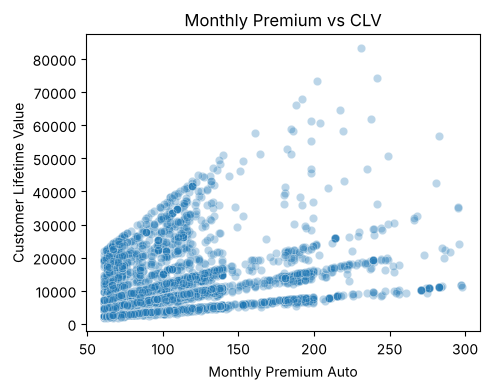

In [10]:
plt.figure(figsize=(5, 4))
sns.scatterplot(data=df, x="Monthly Premium Auto", y="Customer Lifetime Value", alpha=0.3)
plt.title("Monthly Premium vs CLV")
plt.tight_layout()
plt.savefig("../images/premium_vs_clv.png", dpi=120)
plt.show()

**What it tells the manager:** Customers who pay a higher monthly premium tend to have a higher CLV. This is a sensible link, because a higher premium means more income for the company every month.

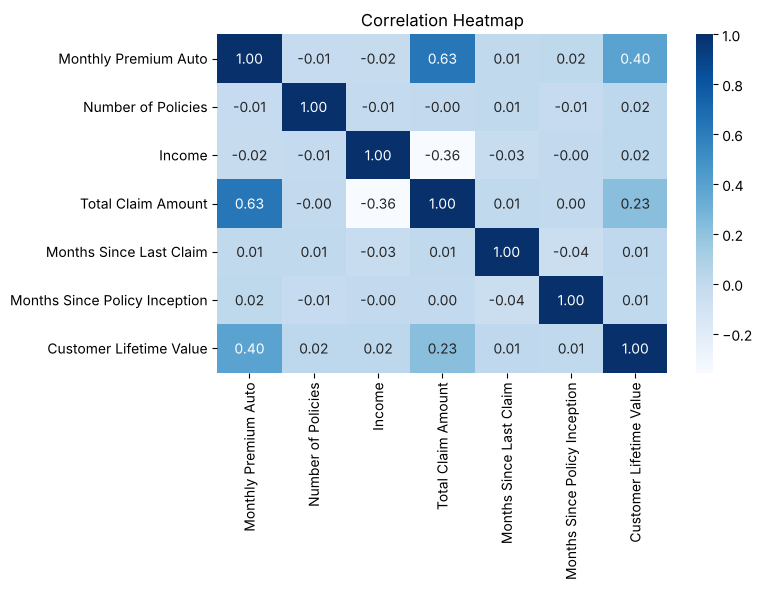

In [11]:
num_cols = ["Monthly Premium Auto", "Number of Policies", "Income", "Total Claim Amount",
            "Months Since Last Claim", "Months Since Policy Inception", "Customer Lifetime Value"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../images/correlation_heatmap.png", dpi=120)
plt.show()

**What it tells the manager:** Monthly Premium (0.40) and Total Claim Amount (0.23) have the strongest straight-line link with CLV. Income and months-since variables show almost no straight-line link. Simple correlation can miss non-linear patterns, which is one reason a Random Forest model works better than a straight-line model here.

## Part D - Machine Learning Model

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

num_features = ["Monthly Premium Auto", "Number of Policies", "Income", "Total Claim Amount",
                "Months Since Last Claim", "Months Since Policy Inception"]
cat_features = ["Coverage", "Vehicle Class"]

X = df[num_features + cat_features]
y = df["Customer Lifetime Value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Train rows: 7307 | Test rows: 1827


We try two models and compare them:
1. **Linear Regression** - a simple baseline.
2. **Random Forest Regressor** - many decision trees averaged together. It can find non-linear patterns.

Categorical columns are turned into 0/1 columns with one-hot encoding. The preprocessing and the model are put in one **Pipeline**, so the saved model can accept raw values from the app.

In [13]:
def make_model(algorithm):
    prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
                             remainder="passthrough")
    return Pipeline([("prep", prep), ("model", algorithm)])

lin_model = make_model(LinearRegression())
lin_model.fit(X_train, y_train)

rf_model = make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1))
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Monthly Premium Auto','Number of Policies','Income',..., 'Months Since Policy Inception','Coverage','Vehicle Class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through.

## Model Evaluation

In [14]:
def evaluate(name, model):
    pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)
    return {"Model": name, "MAE": round(mae), "MSE": round(mse), "RMSE": round(rmse), "R2": round(r2, 3)}

results = pd.DataFrame([evaluate("Linear Regression", lin_model),
                        evaluate("Random Forest", rf_model)])
results

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,4017,43655891,6607,0.153
1,Random Forest,1521,15972553,3997,0.690


**Which metric matters most?** We use **MAE** (average error in dollars) and **R²** (share of CLV differences the model explains).
- MAE is easy for a manager to understand: "on average, our prediction is off by about $X".
- R² tells us how much better the model is than just guessing the average CLV.
- RMSE is also shown. It punishes big mistakes more, which matters because the most valuable customers are the ones we least want to get wrong.

The Random Forest is much better than Linear Regression, so we choose it as the final model.

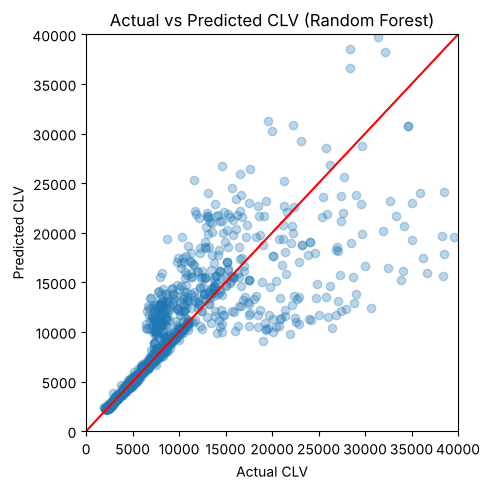

In [15]:
pred = rf_model.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([0, 40000], [0, 40000], color="red")
plt.xlim(0, 40000); plt.ylim(0, 40000)
plt.xlabel("Actual CLV"); plt.ylabel("Predicted CLV")
plt.title("Actual vs Predicted CLV (Random Forest)")
plt.tight_layout()
plt.savefig("../images/actual_vs_predicted.png", dpi=120)
plt.show()

Points close to the red line are good predictions. Most customers are predicted well, but the model struggles with very high CLV customers (they are rare, so the model has few examples to learn from).

### Which factors matter most?

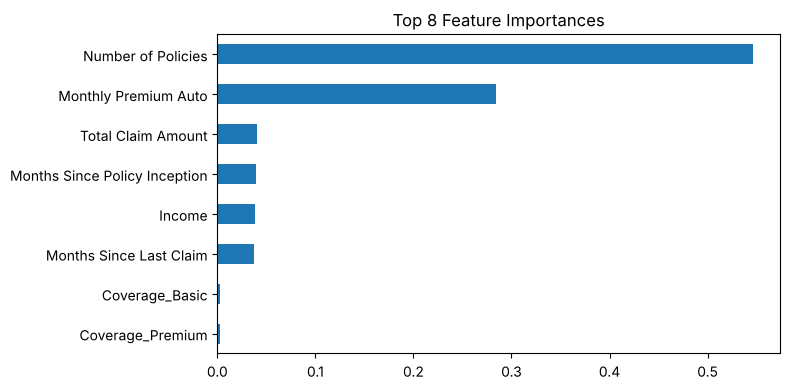

Number of Policies               0.547
Monthly Premium Auto             0.284
Total Claim Amount               0.040
Months Since Policy Inception    0.039
Income                           0.039
Months Since Last Claim          0.037
Coverage_Basic                   0.002
Coverage_Premium                 0.002
dtype: float64

In [16]:
feature_names = rf_model.named_steps["prep"].get_feature_names_out()
importance = pd.Series(rf_model.named_steps["model"].feature_importances_, index=feature_names)
importance = importance.sort_values(ascending=False).head(8)
importance.index = [name.replace("cat__", "").replace("remainder__", "") for name in importance.index]
plt.figure(figsize=(8, 4))
importance.sort_values().plot(kind="barh")
plt.title("Top 8 Feature Importances")
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=120)
plt.show()
importance.round(3)

### Business check: can the model find the top customers?

In [17]:
test_results = pd.DataFrame({"actual": y_test.values, "predicted": pred})
top_cut = test_results["predicted"].quantile(0.8)
top20 = test_results[test_results["predicted"] >= top_cut]
print("Average actual CLV of ALL test customers:", round(test_results["actual"].mean()))
print("Average actual CLV of customers the model ranks in the top 20%:", round(top20["actual"].mean()))
print("Share of total actual CLV held by the model's top 20%:", round(top20["actual"].sum() / test_results["actual"].sum() * 100), "%")

Average actual CLV of ALL test customers: 7934
Average actual CLV of customers the model ranks in the top 20%: 17607
Share of total actual CLV held by the model's top 20%: 44 %


## Part E - Business Interpretation
1. **What does the model predict?** The dollar Customer Lifetime Value of an auto insurance customer, using 8 facts about the customer and policy.
2. **How accurate/useful is it?** The Random Forest explains about 69% of the differences in CLV (R2 = 0.69) and is off by about $1,500 on average (MAE). A straight-line model only reached R2 = 0.15. The model is not perfect, but it is good at RANKING customers: the customers it places in its top 20% have an average actual CLV of about $17,600, compared with about $7,900 for all customers, and they hold about 44% of the total value.
3. **Which factors matter?** Number of Policies (about 55% of the importance) and Monthly Premium (about 28%) matter most. The other six inputs each add only a small amount. In the EDA, luxury vehicles and higher coverage also had clearly higher CLV, but their effect is mostly already captured by the monthly premium.
4. **What decision can be made?** Rank customers by predicted CLV. Give the top group retention offers, a dedicated agent and cross-selling (more policies, higher coverage). Give the bottom group low-cost automated marketing.
5. **Limitations:** (a) The data is from one company and one period, so results may not hold for other markets. (b) The data looks partly synthetic: for example, customers with exactly 2 policies have a much higher average CLV than customers with 3 or more, which is unusual in real life. The model learns this pattern, so we should check it on real data before trusting it. (c) Very high CLV customers are rare, so the model is weaker for them. (d) The model shows patterns, not cause and effect. (e) Gender, marital status and similar personal traits were left out to avoid unfair treatment.
6. **If the prediction is wrong:** If we OVER-predict, we may waste retention money on a customer who is not that valuable. If we UNDER-predict, we may treat a valuable customer poorly and lose them to a competitor, which is the costlier mistake. So the score should support a human decision and not replace it.


## Part G - Save the Model

In [18]:
import joblib
joblib.dump(rf_model, "../model.pkl")
print("Model saved as model.pkl")

# quick check: load it back and predict for one new customer
loaded = joblib.load("../model.pkl")
example = pd.DataFrame([{"Monthly Premium Auto": 100, "Number of Policies": 2, "Income": 50000,
                         "Total Claim Amount": 500, "Months Since Last Claim": 12,
                         "Months Since Policy Inception": 24, "Coverage": "Basic", "Vehicle Class": "SUV"}])
print("Example prediction: $", round(loaded.predict(example)[0]))

Model saved as model.pkl
Example prediction: $ 17018
